# BT4012 · 10 · Temporal holdout evaluation

**Purpose:** evaluate the previously selected model configurations and monthly update policies on the reserved temporal period, months 6–7. This notebook does not tune hyperparameters, seeds, averaging weights, sampling ratios or policies using those results.

Two related questions:

1. **Model comparison:** full-data LightGBM, single RUS CatBoost (seed 42), and the equally weighted three-seed RUS CatBoost ensemble. Each trains on months 0–4 and selects its own cutoff on month 5.
2. **Policy comparison:** frozen CatBoost ensemble, threshold-only updates, and retraining plus threshold updates. All start identically in month 6; month 7 supplies one update comparison.

**Reporting:** AP; ROC-AUC; retrospective recall at 5% FPR; recall, precision, realised FPR and workload at the previously selected cutoff; and exact top-1%/2%/5% review capacity. AP remains the ranking criterion inherited from development. Do not select a new winner and describe the same holdout as an independent confirmation of that choice.

**Prior exposure:** a teammate has already examined months 6–7. Describe this as a fixed-protocol evaluation on the reserved temporal period, with prior team exposure disclosed—not a wholly unseen team-wide test.

Run top to bottom. The notebook refits seven models from the existing prepared dataset; it does not require saved joblib files from earlier notebooks. Refitting avoids pickle-version incompatibility. Package versions, row fingerprints and exact thresholds are saved for reproducibility; bitwise equality with older environments is not guaranteed.


## 1. Predeclared timeline

### A. Static model comparison

All three model choices train on months **0–4**, calibrate the decision cutoff on month **5**, and retain the same model/cutoff throughout months **6–7**. The standalone CatBoost is the seed-42 member of the ensemble; it is not selected again using test performance.

### B. Monthly policy comparison

| Policy | Month 6 | Month 7 |
|---|---|---|
| Frozen | Fit 0–4; cutoff from 5 | Keep the same model and cutoff |
| Threshold only | Same initial ensemble and cutoff | Keep the model; cutoff from 6 |
| Retrain + threshold | Same initial ensemble and cutoff | Refit on 0–5; cutoff from 6 |

**Label availability:** assume month 6's fraud outcomes are available before month 7 is scored. BAF has no label-resolution timestamps; this is a simulation assumption. Month 6 is used as calibration data only for the two adaptive policies' month-7 decisions. It remains an evaluation month for their earlier month-6 decisions.

The refreshed model never trains on month 6, which is held out for its cutoff. This is a sequential evaluation with a predefined update rule, not a static test in which every test label remains unused forever. Month-7 labels never fit a model or choose a deployed cutoff.

All configurations and the policy schedule are written before loading months 6–7. Refresh-model fitting uses only months 0–5 and is completed before inspecting reserved-period performance. Earlier labels are not used to choose a different policy after seeing the results.


## 2. Paths

**Colab:** `MyDrive/BT4012_grp_proj/processed/baf_clean.parquet` and `preparation_manifest.json`.

**Local:** put this notebook under `notebooks/` and those prepared files under `data/processed/`. Set `LOCAL_REPO_ROOT` if needed. No raw CSV or earlier fitted-model artifact is read.

Every run writes to a fresh `results/temporal_holdout/<run>/` and `artifacts/temporal_holdout/<run>/`. Keep row-level predictions and model binaries out of ordinary Git commits.


In [1]:
import sys
from pathlib import Path

# Detect the runtime; local execution does not require google.colab.
IN_COLAB = 'google.colab' in sys.modules

# Colab: keep Base.csv directly inside this existing Drive project folder.
DRIVE_PROJECT_DIR = Path('/content/drive/MyDrive/BT4012_grp_proj')

# Local: normally leave None; set an absolute repo path if auto-detection fails.
LOCAL_REPO_ROOT = None

if IN_COLAB:
    from google.colab import drive

    drive.mount('/content/drive')
    PROJECT_DIR = DRIVE_PROJECT_DIR
    RAW_PATH = PROJECT_DIR / 'Base.csv'
    PROCESSED_DIR = PROJECT_DIR / 'processed'
else:
    if LOCAL_REPO_ROOT is not None:
        PROJECT_DIR = Path(LOCAL_REPO_ROOT).expanduser().resolve()
    else:
        working_dir = Path.cwd().resolve()
        candidates = [working_dir, *working_dir.parents]
        PROJECT_DIR = next(
            (
                candidate
                for candidate in candidates
                if (candidate / 'notebooks').is_dir()
                and (candidate / 'data').is_dir()
            ),
            working_dir,
        )

    RAW_PATH = PROJECT_DIR / 'data' / 'Base.csv'
    PROCESSED_DIR = PROJECT_DIR / 'data' / 'processed'

CLEAN_PATH = PROCESSED_DIR / 'baf_clean.parquet'
MANIFEST_PATH = PROCESSED_DIR / 'preparation_manifest.json'

print('Runtime:', 'Google Colab' if IN_COLAB else 'Local Python')
print('Project:', PROJECT_DIR)
print('Raw CSV:', RAW_PATH)
print('Prepared data:', CLEAN_PATH)


Mounted at /content/drive
Runtime: Google Colab
Project: /content/drive/MyDrive/BT4012_grp_proj
Raw CSV: /content/drive/MyDrive/BT4012_grp_proj/Base.csv
Prepared data: /content/drive/MyDrive/BT4012_grp_proj/processed/baf_clean.parquet


## 3. Dependencies and fixed configurations

Colab installs missing dependencies. Locally install `numpy pandas scikit-learn matplotlib joblib pyarrow catboost lightgbm ipython` into the notebook kernel environment.

**LightGBM:** full eligible data, no class weighting; 300 trees, 15 leaves, minimum child samples 100, learning rate 0.05; seed 42. This reproduces the selected baseline configuration carried through the earlier notebooks.

**CatBoost:** all frauds plus ten sampled legitimate applications per fraud; 600 iterations, depth 4, learning rate 0.05, L2 3. Seeds 42/43/44; equal-weight averaging. No early stopping, calibration of probabilities or new search.

Seven fits: one baseline LightGBM, three initial CatBoost members and three refreshed CatBoost members. The latter use expanded history; the comparison does not isolate extra sample size from recency.


In [2]:
import importlib.util
import subprocess

required_packages = {'numpy': 'numpy', 'pandas': 'pandas', 'sklearn': 'scikit-learn',
                     'matplotlib': 'matplotlib', 'joblib': 'joblib', 'pyarrow': 'pyarrow>=14',
                     'catboost': 'catboost>=1.2', 'lightgbm': 'lightgbm>=4'}
missing = [package for module, package in required_packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    if IN_COLAB:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
    else:
        raise ImportError('Install into this kernel: python -m pip install ' + ' '.join(missing))

import hashlib
import json
import platform
import time
import warnings
from datetime import datetime, timezone
from uuid import uuid4

import joblib
import catboost
import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

SEEDS = [42, 43, 44]
N_JOBS = 2
SAVE_MODELS = True
VERIFY_CHECKSUM = True
INITIAL_TRAIN_MONTHS = [0, 1, 2, 3, 4]
REFRESH_TRAIN_MONTHS = [0, 1, 2, 3, 4, 5]
EVALUATION_MONTHS = [6, 7]
FPR_TARGET = 0.05
REVIEW_CAPACITIES = [0.01, 0.02, 0.05]
NEGATIVES_PER_POSITIVE = 10
FRAUD_PARAMS = {'iterations': 600, 'depth': 4}
MODEL_NAMES = ['lightgbm_full_seed42', 'catboost_rus_seed42', 'catboost_rus_mean3']
POLICIES = ['frozen', 'threshold_only', 'retrain_and_threshold']

run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid4().hex[:6]
RESULTS_DIR = PROJECT_DIR / 'results' / 'temporal_holdout' / run_id
ARTIFACTS_DIR = PROJECT_DIR / 'artifacts' / 'temporal_holdout' / run_id
FIGURES_DIR = RESULTS_DIR / 'figures'
for directory in [RESULTS_DIR, ARTIFACTS_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=False)
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 200})
print('Seven fixed model fits; no tuning.')
print('Results:', RESULTS_DIR)


Seven fixed model fits; no tuning.
Results: /content/drive/MyDrive/BT4012_grp_proj/results/temporal_holdout/20261117T161329Z_88d26a


## 4. Verify preparation and load months 0–5

The file checksum reads bytes for provenance; only development rows are loaded at this stage. Preserve the preparation manifest's exact features and missing-value representation. Cutoff selection and model fitting will be completed according to the declared schedule before displaying evaluation results.


In [3]:
def file_sha256(path):
    """Return a chunked checksum without materialising the entire file in memory."""
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


if not CLEAN_PATH.is_file() or not MANIFEST_PATH.is_file():
    raise FileNotFoundError('Run data preparation first with the configured project paths.')
manifest = json.loads(MANIFEST_PATH.read_text())
assert manifest['schema_version'] == 1
if VERIFY_CHECKSUM and file_sha256(CLEAN_PATH) != manifest['prepared_sha256']:
    raise ValueError('Prepared file checksum differs from its manifest.')
TARGET, MONTH, ROW_ID = manifest['target'], manifest['month_column'], manifest['row_id_column']
FEATURES = manifest['features']
NUMERICAL, CATEGORICAL = manifest['numerical_features'], manifest['categorical_features']
assert set(FEATURES) == set(NUMERICAL + CATEGORICAL)
assert not set(FEATURES) & {TARGET, MONTH, ROW_ID}
assert manifest['split_months']['train'] == INITIAL_TRAIN_MONTHS
assert manifest['split_months']['validation'] == [5]
assert manifest['split_months']['test'] == EVALUATION_MONTHS


def load_months(months):
    """Read only specified months with the same schema checks at each stage."""
    frame = pd.read_parquet(CLEAN_PATH, filters=[(MONTH, 'in', months)])
    if list(frame.columns) != manifest['columns']:
        raise ValueError('Prepared columns differ from the manifest.')
    assert frame[ROW_ID].is_unique and not frame[ROW_ID].isna().any()
    assert sorted(frame[MONTH].unique().tolist()) == sorted(months)
    assert frame[TARGET].isin([0, 1]).all()
    assert all(g[TARGET].nunique() == 2 for _, g in frame.groupby(MONTH))
    for column in CATEGORICAL:
        frame[column] = frame[column].astype(object).where(frame[column].notna(), np.nan)
    return frame.sort_values(ROW_ID).reset_index(drop=True)


development = load_months(REFRESH_TRAIN_MONTHS)
history = development[development[MONTH].isin(INITIAL_TRAIN_MONTHS)].copy()
calibration5 = development[development[MONTH].eq(5)].copy()
assert len(history) == manifest['split_counts']['train']
assert len(calibration5) == manifest['split_counts']['validation']
print('Initial training applications:', len(history))
print('Month-5 calibration applications:', len(calibration5))


Initial training applications: 675666
Month-5 calibration applications: 119323


## 5. Model and metric helpers

Preprocessing matches the preceding experiments: native numeric missing values; constant categorical missing token; CatBoost native categorical inputs; LightGBM ordinal categorical codes with explicit categorical feature positions. Learned categorical encodings are fitted separately within each eligible training set.

A deployed cutoff is chosen on its specified past calibration month. Retrospective recall@5% FPR uses the evaluated labels only to describe the ROC operating point. It never replaces the deployed cutoff.


In [4]:
def make_catboost(params, seed):
    """Build the same preprocessing and CatBoost setup used in Stage C1."""
    preprocessing = ColumnTransformer([
        ('numeric', 'passthrough', NUMERICAL),
        ('categorical', SimpleImputer(
            strategy='constant', fill_value='__MISSING__', keep_empty_features=True,
        ), CATEGORICAL),
    ])

    classifier = CatBoostClassifier(
        loss_function='Logloss', iterations=params['iterations'], depth=params['depth'],
        learning_rate=0.05, l2_leaf_reg=3.0, boosting_type='Plain', task_type='CPU',
        cat_features=list(range(len(NUMERICAL), len(NUMERICAL) + len(CATEGORICAL))),
        random_seed=seed, thread_count=N_JOBS, verbose=False, allow_writing_files=False,
    )

    return Pipeline([('preprocessing', preprocessing), ('classifier', classifier)])


def json_safe(value):
    """Convert NumPy values and nonfinite floats to portable JSON values."""
    if isinstance(value, dict):
        return {k: json_safe(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_safe(v) for v in value]
    if isinstance(value, np.ndarray):
        return json_safe(value.tolist())
    if isinstance(value, (float, np.floating)) and not np.isfinite(value):
        return None
    if isinstance(value, np.generic):
        return value.item()
    return value


def write_json(name, payload):
    """Write run metadata without nonstandard NaN/Infinity JSON literals."""
    (RESULTS_DIR / name).write_text(json.dumps(json_safe(payload), indent=2, allow_nan=False))


In [5]:
def make_lightgbm():
    """Recreate the full-data unweighted LightGBM reference configuration."""
    categorical_pipeline = Pipeline([
        ('impute', SimpleImputer(strategy='constant', fill_value='__MISSING__', keep_empty_features=True)),
        ('encode', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, dtype=np.int32)),
    ])
    preprocessing = ColumnTransformer([
        ('numeric', 'passthrough', NUMERICAL), ('categorical', categorical_pipeline, CATEGORICAL),
    ])
    classifier = LGBMClassifier(
        objective='binary', n_estimators=300, learning_rate=0.05, num_leaves=15,
        min_child_samples=100, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        class_weight=None, scale_pos_weight=1.0, random_state=42, n_jobs=N_JOBS, verbosity=-1,
    )
    return Pipeline([('preprocessing', preprocessing), ('classifier', classifier)])


fit_records = []


def fit_recorded(model, subset, name, train_months, seed, fit_arguments=None):
    """Fit an already specified estimator and save its provenance and warnings."""
    assert set(subset[MONTH].unique()) == set(train_months)
    started = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(subset[FEATURES], subset[TARGET], **(fit_arguments or {}))
    elapsed = time.perf_counter() - started
    fit_warnings = list(dict.fromkeys(str(w.message) for w in caught))
    for warning in fit_warnings:
        print(f'WARNING [{name}]: {warning}')
    ids = subset[ROW_ID].to_numpy(dtype='<i8')
    subset[[ROW_ID]].to_parquet(ARTIFACTS_DIR / f'{name}_train_ids.parquet', index=False)
    if SAVE_MODELS:
        joblib.dump(model, ARTIFACTS_DIR / f'{name}.joblib', compress=3)
    fit_records.append({
        'name': name, 'seed': seed, 'train_months': train_months, 'training_rows': len(subset),
        'training_frauds': int(subset[TARGET].sum()), 'training_ids_sha256': hashlib.sha256(ids.tobytes()).hexdigest(),
        'fit_seconds': elapsed, 'warnings': fit_warnings,
        'model_file': f'{name}.joblib' if SAVE_MODELS else None,
        'classifier_parameters': model.named_steps['classifier'].get_params(),
    })
    write_json('fit_records.json', fit_records)
    print(f'{name}: {len(subset):,} rows; {elapsed:.1f}s')
    return model


def fit_catboost_members(pool, train_months, prefix):
    """Retain all frauds and independently undersample legitimate rows for each seed."""
    pool = pool.sort_values(ROW_ID)
    positive = np.flatnonzero(pool[TARGET].to_numpy() == 1)
    negative = np.flatnonzero(pool[TARGET].to_numpy() == 0)
    n_negative = NEGATIVES_PER_POSITIVE * len(positive)
    assert n_negative <= len(negative)
    members = []
    for seed in SEEDS:
        order = np.random.default_rng(seed).permutation(negative)
        selected = np.concatenate([positive, order[:n_negative]])
        subset = pool.iloc[selected].sort_values(ROW_ID)
        members.append(fit_recorded(make_catboost(FRAUD_PARAMS, seed), subset,
                                   f'{prefix}_seed_{seed}', train_months, seed))
    return members


def mean_scores(members, frame):
    """Average fixed member probabilities; no fitted meta-model or weight tuning."""
    scores = np.mean([m.predict_proba(frame[FEATURES])[:, 1] for m in members], axis=0)
    assert np.isfinite(scores).all() and ((scores >= 0) & (scores <= 1)).all()
    return scores


In [6]:
def at_threshold(y_true, scores, threshold):
    """
    Return confusion counts and operating metrics at an unchanged score cutoff.
    A score equal to the cutoff is flagged; divisions with zero denominators return 0.
    """
    flagged = np.asarray(scores) >= threshold
    positive = np.asarray(y_true) == 1

    tp = int(np.sum(flagged & positive))
    fp = int(np.sum(flagged & ~positive))
    fn = int(np.sum(~flagged & positive))
    tn = int(np.sum(~flagged & ~positive))

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0

    return {
        'tp': tp,
        'fp': fp,
        'fn': fn,
        'tn': tn,
        'precision': precision,
        'recall': recall,
        'f1': 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        'fpr': fp / (fp + tn) if fp + tn else 0.0,
        'alert_rate': float(flagged.mean()),
    }


def threshold_for_fpr(y_true, scores, target_fpr):
    """
    Choose the least restrictive empirical cutoff satisfying an FPR ceiling.

    Evaluate every distinct ROC threshold on the supplied labeled split. This is
    deployable when supplied validation labels; using test labels instead defines
    a retrospective benchmark and must not be confused with a deployment threshold.
    """
    fpr, _, thresholds = roc_curve(y_true, scores, drop_intermediate=False)
    eligible = np.flatnonzero(fpr <= target_fpr)

    return float(thresholds[eligible[-1]])


def capacity_table(y_true, scores, capacities, tie_breakers):
    """
    Evaluate fraud captured when only an exact top-scoring budget is reviewed.

    Rank by descending score, then a label-independent tie breaker. Return review
    counts, precision, recall and true/false positives standardized per 10,000 apps.
    """
    y_true = np.asarray(y_true)
    order = np.lexsort((tie_breakers, -np.asarray(scores)))
    rows = []

    for capacity in capacities:
        n_review = int(np.floor(capacity * len(y_true)))
        reviewed_labels = y_true[order[:n_review]]
        tp = int(reviewed_labels.sum())
        fp = n_review - tp
        total_frauds = int(y_true.sum())

        rows.append({
            'capacity': capacity,
            'reviews': n_review,
            'precision': tp / n_review if n_review else 0.0,
            'recall': tp / total_frauds if total_frauds else 0.0,
            'frauds_flagged': tp,
            'legitimate_reviewed': fp,
            'frauds_missed': total_frauds - tp,
            'frauds_flagged_per_10000': 10000 * tp / len(y_true),
            'legitimate_reviewed_per_10000': 10000 * fp / len(y_true),
        })

    return pd.DataFrame(rows)


def ranking_metrics(y_true, scores, model_name):
    """Return ranking metrics; recall-at-FPR uses labels from this evaluation split."""
    recall_at_fpr = np.nan

    if model_name != 'dummy':
        benchmark_threshold = threshold_for_fpr(y_true, scores, FPR_TARGET)
        recall_at_fpr = at_threshold(y_true, scores, benchmark_threshold)['recall']

    return {
        'average_precision': float(average_precision_score(y_true, scores)),
        'roc_auc': float(roc_auc_score(y_true, scores)),
        'recall_at_target_fpr_benchmark': recall_at_fpr,
    }


In [7]:
threshold_records = []


def record_cutoff(name, frame, scores, calibration_month, training_months):
    """Select and record a cutoff using only the declared calibration month's labels."""
    assert frame[MONTH].eq(calibration_month).all()
    assert max(training_months) < calibration_month
    threshold = threshold_for_fpr(frame[TARGET].to_numpy(), scores, FPR_TARGET)
    at = at_threshold(frame[TARGET].to_numpy(), scores, threshold)
    assert at['fpr'] <= FPR_TARGET + 1e-12
    threshold_records.append({
        'name': name, 'train_months': training_months, 'calibration_month': calibration_month,
        'cutoff': threshold, 'comparison': '>=', 'no_alert_cutoff': bool(np.isposinf(threshold)),
        'calibration_fpr': at['fpr'], 'calibration_recall': at['recall'],
    })
    write_json('threshold_history.json', threshold_records)
    return threshold


def evaluate_scores(frame, scores, cutoff):
    """Separate retrospective ranking metrics from decisions at the past-selected cutoff."""
    labels = frame[TARGET].to_numpy()
    assert len(scores) == len(frame) and np.isfinite(scores).all()
    benchmark = threshold_for_fpr(labels, scores, FPR_TARGET)
    operating = at_threshold(labels, scores, cutoff)
    return {
        'applications': len(frame), 'frauds': int(labels.sum()),
        'average_precision': average_precision_score(labels, scores), 'roc_auc': roc_auc_score(labels, scores),
        'retrospective_recall_at_5fpr': at_threshold(labels, scores, benchmark)['recall'],
        'deployed_cutoff': cutoff,
        **{'deployed_' + k: v for k, v in operating.items()},
        'frauds_caught_per_10000': 10000 * operating['tp'] / len(frame),
        'legitimate_flagged_per_10000': 10000 * operating['fp'] / len(frame),
    }


## 6. Record protocol, fit models and select month-5 cutoffs

The protocol is saved before any months 6–7 are loaded. All seven fits use only months 0–5. The expanded-history ensemble is a predeclared month-7 update, not a model selected because of month-6 performance.

The initial seed-42 CatBoost is reused as the single-model comparator. Its saved month-5 AP can be compared with prior runs as a reproducibility diagnostic; differences are not an invitation to retune on the evaluation period.


In [8]:
run_info = {
    'status': 'protocol_recorded', 'evaluation_months': EVALUATION_MONTHS,
    'prepared_sha256': manifest['prepared_sha256'], 'preparation_id': manifest['preparation_id'],
    'features': FEATURES, 'initial_train_months': INITIAL_TRAIN_MONTHS,
    'refresh_train_months': REFRESH_TRAIN_MONTHS, 'seeds': SEEDS,
    'catboost_params': FRAUD_PARAMS, 'sampling_negative_positive_ratio': NEGATIVES_PER_POSITIVE,
    'static_models': MODEL_NAMES, 'policies': POLICIES, 'fpr_target': FPR_TARGET,
    'review_capacities': REVIEW_CAPACITIES,
    'configuration_selection': 'fixed from preceding development experiments; no tuning here',
    'prior_team_test_exposure': True,
    'label_availability': 'preceding-month outcomes available before next month scoring',
    'month6_labels_used_only_for': 'predeclared month7 cutoff updates, evaluation metrics',
    'versions': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
                 'sklearn': sklearn.__version__, 'catboost': catboost.__version__, 'lightgbm': lightgbm.__version__},
}
write_json('run_manifest.json', run_info)

baseline = fit_recorded(make_lightgbm(), history, 'lightgbm_full_seed42', INITIAL_TRAIN_MONTHS, 42,
    {'classifier__categorical_feature': list(range(len(NUMERICAL), len(NUMERICAL) + len(CATEGORICAL)))})
initial_members = fit_catboost_members(history, INITIAL_TRAIN_MONTHS, 'initial_catboost')
initial_model_sets = {
    'lightgbm_full_seed42': [baseline],
    'catboost_rus_seed42': [initial_members[0]],
    'catboost_rus_mean3': initial_members,
}
initial_cutoffs = {}
calibration_predictions = calibration5[[ROW_ID, MONTH, TARGET]].copy()
calibration_rows = []
for name, members in initial_model_sets.items():
    scores = mean_scores(members, calibration5)
    initial_cutoffs[name] = record_cutoff(name + '_month5', calibration5, scores, 5, INITIAL_TRAIN_MONTHS)
    calibration_predictions[name] = scores
    calibration_rows.append({'model': name, **evaluate_scores(calibration5, scores, initial_cutoffs[name])})
calibration_predictions.to_parquet(ARTIFACTS_DIR / 'month5_calibration_predictions.parquet', index=False)
pd.DataFrame(calibration_rows).to_csv(RESULTS_DIR / 'month5_calibration_metrics.csv', index=False)
display(pd.DataFrame(calibration_rows)[['model', 'average_precision', 'retrospective_recall_at_5fpr', 'deployed_cutoff']])

# The update rule is fixed. Training now uses only information available before month 7.
refreshed_members = fit_catboost_members(development, REFRESH_TRAIN_MONTHS, 'refreshed_catboost')
assert len(fit_records) == 7
run_info['status'] = 'models_fitted_initial_cutoffs_recorded'
write_json('run_manifest.json', run_info)


lightgbm_full_seed42: 675,666 rows; 56.4s
WARNING [initial_catboost_seed_42]: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
initial_catboost_seed_42: 74,140 rows; 51.2s
WARNING [initial_catboost_seed_43]: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
initial_catboost_seed_43: 74,140 rows; 51.3s
WARNING [initial_catboost_seed_44]: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
initial_catboost_seed_44: 74,140 rows; 50.5s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,model,average_precision,retrospective_recall_at_5fpr,deployed_cutoff
0,lightgbm_full_seed42,0.184986,0.545004,0.028387
1,catboost_rus_seed42,0.197252,0.545712,0.235301
2,catboost_rus_mean3,0.197907,0.548547,0.236840


refreshed_catboost_seed_42: 89,661 rows; 60.9s
WARNING [refreshed_catboost_seed_43]: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
refreshed_catboost_seed_43: 89,661 rows; 66.6s
WARNING [refreshed_catboost_seed_44]: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
refreshed_catboost_seed_44: 89,661 rows; 61.4s


## 7. Score month 6, then apply the predeclared cutoff-update rule

Score month 6 with the initial models. For the adaptive policies' month-7 decisions, use month-6 labels to set cutoffs on the **unchanged** initial ensemble and the **expanded-history** ensemble separately.

The refreshed ensemble's scores on month 6 are calibration scores, not its month-6 deployment predictions. Month-6 deployment uses the initial ensemble for all three policies. No policy choice, hyperparameter or averaging weight is changed in response to month-6 results.


In [9]:
month6 = load_months([6])
assert not set(month6[ROW_ID]) & set(development[ROW_ID])
scores6 = {name: mean_scores(members, month6) for name, members in initial_model_sets.items()}
refreshed_calibration6 = mean_scores(refreshed_members, month6)
threshold_only_cutoff7 = record_cutoff('threshold_only_month7', month6, scores6['catboost_rus_mean3'],
                                      6, INITIAL_TRAIN_MONTHS)
refreshed_cutoff7 = record_cutoff('retrain_and_threshold_month7', month6, refreshed_calibration6,
                                 6, REFRESH_TRAIN_MONTHS)

calibration6_output = month6[[ROW_ID, MONTH, TARGET]].copy()
calibration6_output['initial_ensemble_calibration_score'] = scores6['catboost_rus_mean3']
calibration6_output['refreshed_ensemble_calibration_score'] = refreshed_calibration6
calibration6_output.to_parquet(ARTIFACTS_DIR / 'month6_for_month7_calibration.parquet', index=False)

# All month-7 thresholds are now fixed, before month 7 is loaded or scored.
run_info['status'] = 'month7_cutoffs_recorded'
write_json('run_manifest.json', run_info)
month7 = load_months([7])
assert not set(month7[ROW_ID]) & (set(development[ROW_ID]) | set(month6[ROW_ID]))
assert len(month6) + len(month7) == manifest['split_counts']['test']
scores7 = {name: mean_scores(members, month7) for name, members in initial_model_sets.items()}
refreshed_scores7 = mean_scores(refreshed_members, month7)

monthly_frames = {6: month6, 7: month7}
static_scores = {6: scores6, 7: scores7}
policy_scores = {
    6: {p: scores6['catboost_rus_mean3'] for p in POLICIES},
    7: {'frozen': scores7['catboost_rus_mean3'], 'threshold_only': scores7['catboost_rus_mean3'],
        'retrain_and_threshold': refreshed_scores7},
}
policy_cutoffs = {
    6: {p: initial_cutoffs['catboost_rus_mean3'] for p in POLICIES},
    7: {'frozen': initial_cutoffs['catboost_rus_mean3'], 'threshold_only': threshold_only_cutoff7,
        'retrain_and_threshold': refreshed_cutoff7},
}
print('Reserved-period scores generated under the fixed protocol.')


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Reserved-period scores generated under the fixed protocol.


## 8. Static model comparison: months separately and pooled

For each static model the scoring function and deployed threshold stay unchanged, so pooled ranking metrics are well defined. Pooled recall@5% FPR finds a retrospective cutoff across both months; it is not the same as applying each month's retrospective cutoff separately.

Exact-capacity metrics are computed within each month. Their later aggregate sums those monthly queues; it is not a single retrospectively ranked two-month queue.


In [10]:
static_rows, capacity_rows, policy_rows = [], [], []
for month in EVALUATION_MONTHS:
    frame = monthly_frames[month]
    ties = np.random.default_rng(2026 + month).random(len(frame))
    output = frame[[ROW_ID, MONTH, TARGET]].copy()
    for name in MODEL_NAMES:
        scores = static_scores[month][name]
        cutoff = initial_cutoffs[name]
        static_rows.append({'model': name, 'period': str(month), **evaluate_scores(frame, scores, cutoff)})
        cap = capacity_table(frame[TARGET].to_numpy(), scores, REVIEW_CAPACITIES, ties)
        cap['comparison'], cap['name'], cap['month'] = 'static_model', name, month
        capacity_rows.extend(cap.to_dict('records'))
        output['static_' + name + '_score'] = scores
        output['static_' + name + '_flagged'] = scores >= cutoff
    for policy in POLICIES:
        scores, cutoff = policy_scores[month][policy], policy_cutoffs[month][policy]
        policy_rows.append({'policy': policy, 'month': month, **evaluate_scores(frame, scores, cutoff)})
        cap = capacity_table(frame[TARGET].to_numpy(), scores, REVIEW_CAPACITIES, ties)
        cap['comparison'], cap['name'], cap['month'] = 'update_policy', policy, month
        capacity_rows.extend(cap.to_dict('records'))
        output['policy_' + policy + '_score'] = scores
        output['policy_' + policy + '_flagged'] = scores >= cutoff
    output.to_parquet(ARTIFACTS_DIR / f'month_{month}_predictions.parquet', index=False)

pooled_frame = pd.concat([month6, month7], ignore_index=True)
for name in MODEL_NAMES:
    pooled_scores = np.concatenate([scores6[name], scores7[name]])
    static_rows.append({'model': name, 'period': '6–7 pooled',
                       **evaluate_scores(pooled_frame, pooled_scores, initial_cutoffs[name])})
static_metrics = pd.DataFrame(static_rows)
policy_metrics = pd.DataFrame(policy_rows)
capacity_metrics = pd.DataFrame(capacity_rows)
static_metrics.to_csv(RESULTS_DIR / 'static_model_metrics.csv', index=False)
policy_metrics.to_csv(RESULTS_DIR / 'monthly_policy_metrics.csv', index=False)
capacity_metrics.to_csv(RESULTS_DIR / 'monthly_review_capacity.csv', index=False)

report_columns = ['average_precision', 'retrospective_recall_at_5fpr', 'deployed_recall',
                  'deployed_fpr', 'deployed_precision', 'deployed_alert_rate', 'deployed_tp', 'deployed_fp']
display(static_metrics[['period', 'model'] + report_columns])

# Pooling deployed confusion counts must reproduce the fixed-model pooled result.
for name in MODEL_NAMES:
    rows = static_metrics[static_metrics.model.eq(name)].set_index('period')
    for count in ['tp', 'fp', 'fn', 'tn']:
        col = 'deployed_' + count
        assert rows.loc['6', col] + rows.loc['7', col] == rows.loc['6–7 pooled', col]


,period,model,average_precision,retrospective_recall_at_5fpr,deployed_recall,deployed_fpr,deployed_precision,deployed_alert_rate,deployed_tp,deployed_fp
0,6,lightgbm_full_seed42,0.178885,0.516552,0.573103,0.064506,0.107712,0.071324,831,6884
1,6,catboost_rus_seed42,0.179962,0.536552,0.582759,0.064656,0.109103,0.071602,845,6900
2,6,catboost_rus_mean3,0.183983,0.536552,0.578621,0.064450,0.108721,0.071343,839,6878
3,7,lightgbm_full_seed42,0.210860,0.560224,0.585434,0.055945,0.135407,0.063753,836,5338
4,7,catboost_rus_seed42,0.220854,0.575630,0.591036,0.054446,0.139758,0.062359,844,5195
5,7,catboost_rus_mean3,0.225427,0.578431,0.593838,0.053786,0.141806,0.061749,848,5132
6,6–7 pooled,lightgbm_full_seed42,0.193286,0.539958,0.579222,0.060465,0.120023,0.067748,1667,12222
7,6–7 pooled,catboost_rus_seed42,0.198463,0.552814,0.586866,0.059837,0.122533,0.067235,1689,12095
8,6–7 pooled,catboost_rus_mean3,0.202266,0.554899,0.586171,0.059416,0.123166,0.066811,1687,12010


## 9. Policy comparison: isolate cutoff updates from model refresh

All policies must match in month 6. In month 7, frozen and threshold-only policies use identical scores: ranking metrics and exact-capacity results must match even when deployed recall and FPR differ.

Retrain-plus-threshold versus threshold-only compares model refresh under the same calibration policy. Read deployed recall together with FPR and review workload; extra frauds caught at extra false-positive cost do not establish better ranking.

There is only **one new policy update opportunity**, month 7. Pooled deployed metrics sum the month-specific decisions. Do not compute a single retrospective pooled AP or ROC cutoff for the changing-model policy: its score scales can change across months. The descriptive mean monthly AP below is explicitly a macro average.


In [11]:
assert len(static_metrics) == 9 and len(policy_metrics) == 6
first = policy_metrics[policy_metrics.month.eq(6)]
for col in report_columns:
    assert np.allclose(first[col], first[col].iloc[0])
for month in EVALUATION_MONTHS:
    part = policy_metrics[policy_metrics.month.eq(month)].set_index('policy')
    for col in ['average_precision', 'roc_auc', 'retrospective_recall_at_5fpr']:
        assert np.isclose(part.loc['frozen', col], part.loc['threshold_only', col])
display(policy_metrics[['month', 'policy'] + report_columns])

aggregate_rows = []
for policy in POLICIES:
    part = policy_metrics[policy_metrics.policy.eq(policy)]
    tp, fp, fn, tn = [int(part['deployed_' + k].sum()) for k in ['tp', 'fp', 'fn', 'tn']]
    total = tp + fp + fn + tn
    aggregate_rows.append({
        'policy': policy, 'applications': total, 'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn,
        'pooled_deployed_recall': tp / (tp + fn), 'pooled_deployed_fpr': fp / (fp + tn),
        'pooled_deployed_precision': tp / (tp + fp) if tp + fp else 0.0,
        'review_fraction': (tp + fp) / total,
        'frauds_caught_per_10000': 10000 * tp / total,
        'legitimate_flagged_per_10000': 10000 * fp / total,
        'macro_mean_monthly_ap': part.average_precision.mean(),
    })
policy_aggregate = pd.DataFrame(aggregate_rows)
policy_aggregate.to_csv(RESULTS_DIR / 'policy_aggregate_deployed.csv', index=False)
display(policy_aggregate)

month7_table = policy_metrics[policy_metrics.month.eq(7)].set_index('policy')
differences = []
for a, b, label in [('threshold_only', 'frozen', 'threshold update'),
                    ('retrain_and_threshold', 'threshold_only', 'model refresh with same calibration policy'),
                    ('retrain_and_threshold', 'frozen', 'overall update')]:
    differences.append({'comparison': label,
        **{col + '_difference': float(month7_table.loc[a, col] - month7_table.loc[b, col])
           for col in ['average_precision', 'retrospective_recall_at_5fpr', 'deployed_recall',
                       'deployed_fpr', 'deployed_tp', 'deployed_fp']}})
policy_differences = pd.DataFrame(differences)
policy_differences.to_csv(RESULTS_DIR / 'month7_policy_differences.csv', index=False)
display(policy_differences)


,month,policy,average_precision,retrospective_recall_at_5fpr,deployed_recall,deployed_fpr,deployed_precision,deployed_alert_rate,deployed_tp,deployed_fp
0,6,frozen,0.183983,0.536552,0.578621,0.064450,0.108721,0.071343,839,6878
1,6,threshold_only,0.183983,0.536552,0.578621,0.064450,0.108721,0.071343,839,6878
2,6,retrain_and_threshold,0.183983,0.536552,0.578621,0.064450,0.108721,0.071343,839,6878
3,7,frozen,0.225427,0.578431,0.593838,0.053786,0.141806,0.061749,848,5132
4,7,threshold_only,0.225427,0.578431,0.541317,0.041304,0.163980,0.048677,773,3941
5,7,retrain_and_threshold,0.226676,0.584034,0.555322,0.043746,0.159654,0.051289,793,4174


,policy,applications,tp,fp,fn,tn,pooled_deployed_recall,pooled_deployed_fpr,pooled_deployed_precision,review_fraction,frauds_caught_per_10000,legitimate_flagged_per_10000,macro_mean_monthly_ap
0,frozen,205011,1687,12010,1191,190123,0.586171,0.059416,0.123166,0.066811,82.288267,585.822224,0.204705
1,threshold_only,205011,1612,10819,1266,191314,0.560111,0.053524,0.129676,0.060636,78.629927,527.727780,0.204705
2,retrain_and_threshold,205011,1632,11052,1246,191081,0.567060,0.054677,0.128666,0.061870,79.605485,539.093024,0.205330


,comparison,average_precision_difference,retrospective_recall_at_5fpr_difference,deployed_recall_difference,deployed_fpr_difference,deployed_tp_difference,deployed_fp_difference
0,threshold update,0.000000,0.000000,-0.052521,-0.012482,-75.0,-1191.0
1,model refresh with same calibration policy,0.001249,0.005602,0.014006,0.002442,20.0,233.0
2,overall update,0.001249,0.005602,-0.038515,-0.010040,-55.0,-958.0


## 10. Fixed review budgets and computational cost

A top-K queue assumes a batch of applications is available to rank. It fixes workload without needing fraud labels at decision time; it does not promise a fixed FPR. The labels here are used afterward to measure capture.

The same number of applications is reviewed by every method within each month/budget. Report extra frauds caught and legitimate reviews avoided at that same workload. Do not call these monetary savings: BAF does not provide realised loss or investigation-cost outcomes.


In [12]:
capacity_aggregate = capacity_metrics.groupby(['comparison', 'name', 'capacity']).agg(
    reviews=('reviews', 'sum'), frauds_caught=('frauds_flagged', 'sum'),
    legitimate_reviewed=('legitimate_reviewed', 'sum'), frauds_missed=('frauds_missed', 'sum'),
).reset_index()
capacity_aggregate['precision'] = capacity_aggregate.frauds_caught / capacity_aggregate.reviews
capacity_aggregate['recall'] = capacity_aggregate.frauds_caught / (
    capacity_aggregate.frauds_caught + capacity_aggregate.frauds_missed)
capacity_aggregate['frauds_caught_per_10000'] = 10000 * capacity_aggregate.frauds_caught / len(pooled_frame)
capacity_aggregate['legitimate_reviewed_per_10000'] = 10000 * capacity_aggregate.legitimate_reviewed / len(pooled_frame)
capacity_aggregate.to_csv(RESULTS_DIR / 'review_capacity_aggregate.csv', index=False)
display(capacity_aggregate)

for month in EVALUATION_MONTHS:
    for budget in REVIEW_CAPACITIES:
        part = capacity_metrics[capacity_metrics.month.eq(month) & capacity_metrics.capacity.eq(budget)]
        assert part.reviews.nunique() == 1
        p = part[part.comparison.eq('update_policy')].set_index('name')
        assert p.loc['frozen', 'frauds_flagged'] == p.loc['threshold_only', 'frauds_flagged']

fit_table = pd.DataFrame(fit_records)
fit_table[['name', 'seed', 'training_rows', 'training_frauds', 'fit_seconds']].to_csv(
    RESULTS_DIR / 'model_fit_cost.csv', index=False)
display(fit_table[['name', 'training_rows', 'fit_seconds']])
print('Single CatBoost: one initial member. Ensemble: three initial members.')
print('Refreshed policy: three additional fits before month 7. Threshold-only: no additional model fit.')
print('Fit seconds exclude preprocessing orchestration, scoring, storage and deployment overhead;')
print('they are not measurements of production inference latency.')


,comparison,name,capacity,reviews,frauds_caught,legitimate_reviewed,frauds_missed,precision,recall,frauds_caught_per_10000,legitimate_reviewed_per_10000
0,static_model,catboost_rus_mean3,0.01,2049,633,1416,2245,0.308931,0.219944,30.876392,69.069465
1,static_model,catboost_rus_mean3,0.02,4099,957,3142,1921,0.233472,0.332523,46.680422,153.260069
2,static_model,catboost_rus_mean3,0.05,10250,1516,8734,1362,0.147902,0.526755,73.947252,426.025921
3,static_model,catboost_rus_seed42,0.01,2049,624,1425,2254,0.304539,0.216817,30.437391,69.508465
4,static_model,catboost_rus_seed42,0.02,4099,949,3150,1929,0.231520,0.329743,46.290199,153.650292
5,static_model,catboost_rus_seed42,0.05,10250,1520,8730,1358,0.148293,0.528145,74.142363,425.830809
6,static_model,lightgbm_full_seed42,0.01,2049,607,1442,2271,0.296242,0.210910,29.608167,70.337689
7,static_model,lightgbm_full_seed42,0.02,4099,928,3171,1950,0.226397,0.322446,45.265864,154.674627
8,static_model,lightgbm_full_seed42,0.05,10250,1474,8776,1404,0.143805,0.512161,71.898581,428.074591
9,update_policy,frozen,0.01,2049,633,1416,2245,0.308931,0.219944,30.876392,69.069465


,name,training_rows,fit_seconds
0,lightgbm_full_seed42,675666,56.388620
1,initial_catboost_seed_42,74140,51.190106
2,initial_catboost_seed_43,74140,51.329531
3,initial_catboost_seed_44,74140,50.473791
4,refreshed_catboost_seed_42,89661,60.852920
5,refreshed_catboost_seed_43,89661,66.563743
6,refreshed_catboost_seed_44,89661,61.378697


Single CatBoost: one initial member. Ensemble: three initial members.
Refreshed policy: three additional fits before month 7. Threshold-only: no additional model fit.
Fit seconds exclude preprocessing orchestration, scoring, storage and deployment overhead;
they are not measurements of production inference latency.


## 11. Figures and reproducibility record

Plots separate ranking performance from actual deployed operating points. The dashed 5% line is a calibration target, not a guarantee on either evaluated month.

The persisted manifest and threshold history retain full numeric precision. Do not manually copy a rounded threshold from a displayed table into later scoring code.


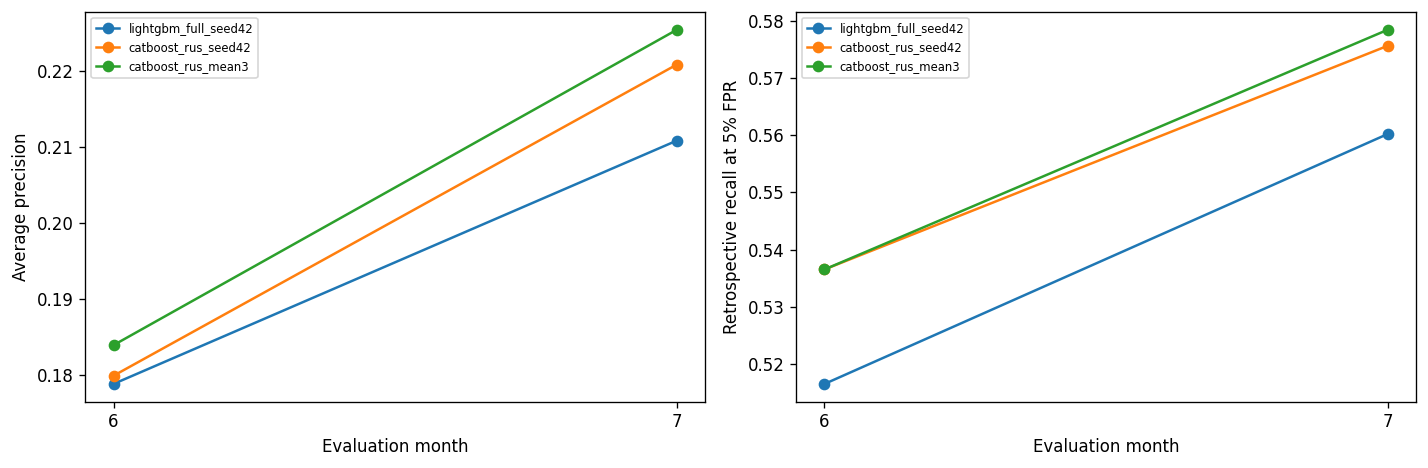

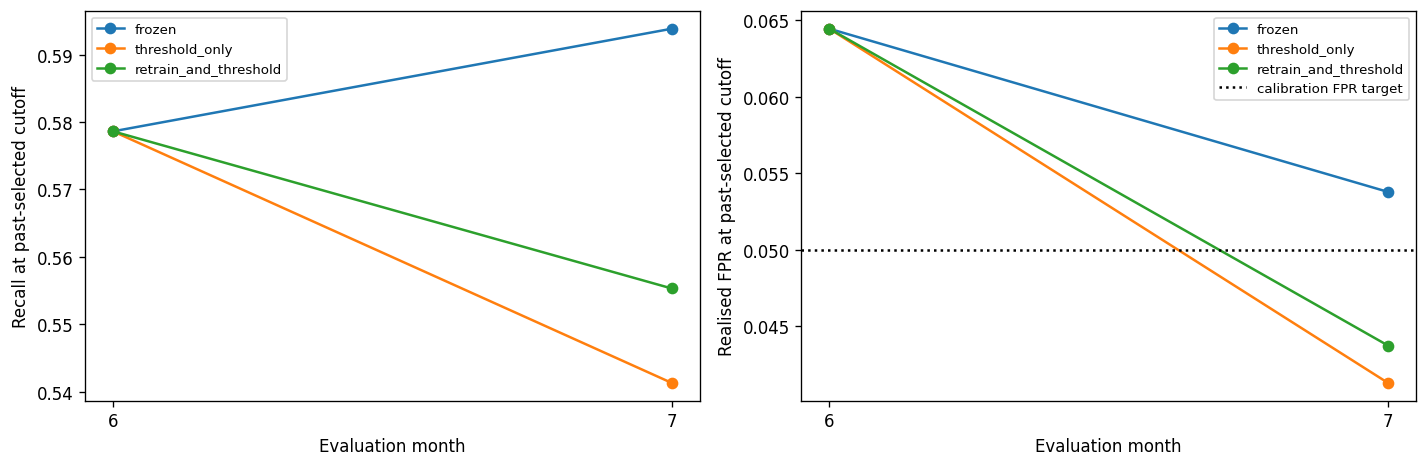

Evaluation complete. No configuration was selected or changed from these results.
Results: /content/drive/MyDrive/BT4012_grp_proj/results/temporal_holdout/20261117T161329Z_88d26a
Artifacts: /content/drive/MyDrive/BT4012_grp_proj/artifacts/temporal_holdout/20261117T161329Z_88d26a


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in MODEL_NAMES:
    part = static_metrics[static_metrics.model.eq(name) & static_metrics.period.isin(['6', '7'])]
    for ax, col in zip(axes, ['average_precision', 'retrospective_recall_at_5fpr']):
        ax.plot(part.period.astype(int), part[col], marker='o', label=name)
for ax, label in zip(axes, ['Average precision', 'Retrospective recall at 5% FPR']):
    ax.set(xlabel='Evaluation month', ylabel=label, xticks=EVALUATION_MONTHS)
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'static_model_ranking.png')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for policy in POLICIES:
    part = policy_metrics[policy_metrics.policy.eq(policy)]
    for ax, col in zip(axes, ['deployed_recall', 'deployed_fpr']):
        ax.plot(part.month, part[col], marker='o', label=policy)
axes[1].axhline(FPR_TARGET, color='black', linestyle=':', label='calibration FPR target')
for ax, label in zip(axes, ['Recall at past-selected cutoff', 'Realised FPR at past-selected cutoff']):
    ax.set(xlabel='Evaluation month', ylabel=label, xticks=EVALUATION_MONTHS)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'deployed_policy_operating_points.png')
plt.show()

run_info.update({
    'status': 'complete', 'completed_fits': len(fit_records),
    'static_model_components': {
        'lightgbm_full_seed42': ['lightgbm_full_seed42'],
        'catboost_rus_seed42': ['initial_catboost_seed_42'],
        'catboost_rus_mean3': [f'initial_catboost_seed_{s}' for s in SEEDS],
    },
    'refreshed_components': [f'refreshed_catboost_seed_{s}' for s in SEEDS],
    'ensemble_member_weights': [1 / len(SEEDS)] * len(SEEDS),
    'thresholds': threshold_records,
    'evaluation_row_sha256': hashlib.sha256(pooled_frame[ROW_ID].to_numpy(dtype='<i8').tobytes()).hexdigest(),
})
write_json('run_manifest.json', run_info)
write_json('preparation_manifest.json', manifest)
print('Evaluation complete. No configuration was selected or changed from these results.')
print('Results:', RESULTS_DIR)
print('Artifacts:', ARTIFACTS_DIR)


## 12. Interpretation checklist

Record findings without assuming the development ranking will repeat:

1. Does the three-CatBoost average improve over single CatBoost and the original LightGBM baseline on each month and pooled? Is the improvement consistent across metrics?
2. At the month-5 cutoff, how much do FPR, recall and workload shift in months 6 and 7?
3. In month 7, does threshold maintenance reduce workload or merely move along the same ROC curve?
4. Does refreshed-model ranking improve beyond the unchanged model? Do fixed-budget counts support the conclusion?
5. What is gained relative to the added models, fitting cost and label-availability requirements?

**Reporting boundaries:** prior team exposure to the reserved period; only one policy update opportunity; assumed outcome availability; expanded history changes sample size and recency together; synthetic data; no measured business loss or real review costs; no formal statistical-significance claim from point differences alone.

A negative result is useful evidence. Do not revise parameters or pick another seed after this run and present the same results as independent confirmation. Any subsequent changes should be documented as additional test-informed exploration requiring new validation evidence.

**Share with the team:** executed notebook, `static_model_metrics.csv`, `monthly_policy_metrics.csv`, `policy_aggregate_deployed.csv`, `month7_policy_differences.csv`, `review_capacity_aggregate.csv`, `threshold_history.json` and `run_manifest.json`. Large prediction parquet and model files remain outside ordinary Git commits.
